# Graph Implementation

In [1]:
class Graph(object):

    def __init__(self, graph_dict=None): # graph_dict is a default parameter 
        """ initializes a graph object 
            If no dictionary or None is given, 
            an empty dictionary will be used
        """
        if graph_dict == None:
            graph_dict = {}
        self.__graph_dict = graph_dict # internal variable `__`

    def vertices(self):
        """ returns the vertices of a graph """
        return list(self.__graph_dict.keys())

    def edges(self):
        """ returns the edges of a graph """
        return self.__generate_edges()

    def add_vertex(self, vertex):
        """ If the vertex is not in 
            self.__graph_dict, a key "vertex" with an empty
            list as a value is added to the dictionary. 
            Otherwise nothing has to be done. 
        """
        if vertex not in self.__graph_dict:
            self.__graph_dict[vertex] = []

    def add_edge(self, edge):
        """ assumes that edge is of type set, tuple or list; 
            between two vertices can be multiple edges
        """
        edge = set(edge)
        (vertex1, vertex2) = tuple(edge)
        if vertex1 in self.__graph_dict:
            self.__graph_dict[vertex1].append(vertex2)
        else:
            self.__graph_dict[vertex1] = [vertex2]

    def __generate_edges(self): #static as it starts with `__`
        """ A static method generating the edges of the 
            graph "graph". Edges are represented as sets 
            with one (a loop back to the vertex `circuit`) or two 
            vertices 
        """
        edges = []
        for vertex in self.__graph_dict: # keys
            for neighbour in self.__graph_dict[vertex]: # value, can be one loop
                if {neighbour, vertex} not in edges:
                    edges.append({vertex, neighbour})
        return edges

    def __str__(self):
        res = "vertices: "
        for k in self.__graph_dict:
            res += str(k) + " "
        res += "\nedges: "
        for edge in self.__generate_edges():
            res += str(edge) + " "
        return res
    
    def find_path(self, start_vertex, end_vertex, path=None): # recursive function
        """ find a path from start_vertex to end_vertex 
            in graph """
        if path == None: # base case or start
            path = []
        graph = self.__graph_dict
        path = path + [start_vertex]
        if start_vertex == end_vertex: # final case
            return path
        if start_vertex not in graph: # no edge found
            return None
        for vertex in graph[start_vertex]:
            if vertex not in path:
                extended_path = self.find_path(vertex, 
                                               end_vertex, 
                                               path)
                if extended_path: 
                    return extended_path
        return None
    
    def vertex_degree(self, vertex): # TO BE DISCUSSED in SECTION
        """ The degree of a vertex is the number of edges connecting
            it, i.e. the number of adjacent vertices. Loops are counted 
            double, i.e. every occurence of vertex in the list 
            of adjacent vertices. """ 
        adj_vertices =  self.__graph_dict[vertex]
        degree = len(adj_vertices) + adj_vertices.count(vertex)
        return degree

    def find_shortest_path(self, start_vertex, end_vertex, path=None): # assignment
        pass

In [2]:
g = { "a" : ["d"],
      "b" : ["c"],
      "c" : ["b", "c", "d", "e"],
      "d" : ["a", "c"],
      "e" : ["c"],
      "f" : []
    }


graph = Graph(g)

print("Vertices of graph:")
print(graph.vertices())



Vertices of graph:
['a', 'b', 'c', 'd', 'e', 'f']


In [3]:
print("Edges of graph:")
print(graph.edges())


Edges of graph:
[{'d', 'a'}, {'c', 'b'}, {'c'}, {'d', 'c'}, {'e', 'c'}]


In [4]:
print("Add vertex:")
graph.add_vertex("z")

print("Vertices of graph:")
print(graph.vertices())


Add vertex:
Vertices of graph:
['a', 'b', 'c', 'd', 'e', 'f', 'z']


In [5]:

print("Add an edge:")
graph.add_edge({"a","z"})

print("Vertices of graph:")
print(graph.vertices())

print("Edges of graph:")
print(graph.edges())



Add an edge:
Vertices of graph:
['a', 'b', 'c', 'd', 'e', 'f', 'z']
Edges of graph:
[{'d', 'a'}, {'c', 'b'}, {'c'}, {'d', 'c'}, {'e', 'c'}, {'z', 'a'}]


In [6]:

print('Adding an edge {"x","y"} with new vertices:')
graph.add_edge({"x","y"})
print("Vertices of graph:")
print(graph.vertices())
print("Edges of graph:")
print(graph.edges())


Adding an edge {"x","y"} with new vertices:
Vertices of graph:
['a', 'b', 'c', 'd', 'e', 'f', 'z', 'x']
Edges of graph:
[{'d', 'a'}, {'c', 'b'}, {'c'}, {'d', 'c'}, {'e', 'c'}, {'z', 'a'}, {'x', 'y'}]


# Find Path in Graph

In [7]:
g = { "a" : ["d"],
      "b" : ["c"],
      "c" : ["b", "c", "d", "e"],
      "d" : ["a", "c"],
      "e" : ["c"],
      "f" : []
    }


graph = Graph(g)

print("Vertices of graph:")
print(graph.vertices())

print("Edges of graph:")
print(graph.edges())


print('The path from vertex "a" to vertex "b":')
path = graph.find_path("a", "b")
print(path)

print('The path from vertex "a" to vertex "f":')
path = graph.find_path("a", "f")
print(path)

print('The path from vertex "c" to vertex "c":')
path = graph.find_path("c", "c")
print(path)

Vertices of graph:
['a', 'b', 'c', 'd', 'e', 'f']
Edges of graph:
[{'d', 'a'}, {'c', 'b'}, {'c'}, {'d', 'c'}, {'e', 'c'}]
The path from vertex "a" to vertex "b":
['a', 'd', 'c', 'b']
The path from vertex "a" to vertex "f":
None
The path from vertex "c" to vertex "c":
['c']


In [8]:
print(graph.vertex_degree("a"))
print(graph.vertex_degree("b"))
print(graph.vertex_degree("c"))


1
1
5


# Graph Application

In [9]:
# Must install first numpy and pandas packages and download data.csv file and be in same folder
import pandas as pd
import numpy as np
data = pd.read_csv('data.csv')

In [10]:
# first 5 records from data
data.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,AirTime,Origin,Dest,Distance
0,2008,1,3,4,2003.0,1955,2211.0,2225,116.0,IAD,TPA,810
1,2008,1,3,4,754.0,735,1002.0,1000,113.0,IAD,TPA,810
2,2008,1,3,4,628.0,620,804.0,750,76.0,IND,BWI,515
3,2008,1,3,4,926.0,930,1054.0,1100,78.0,IND,BWI,515
4,2008,1,3,4,1829.0,1755,1959.0,1925,77.0,IND,BWI,515


In [12]:
import networkx as nx
df = nx.from_pandas_edgelist(data, source='Origin', target='Dest', edge_attr=True)

In [13]:
df.nodes()

NodeView(('IAD', 'TPA', 'IND', 'BWI', 'JAX', 'LAS', 'MCI', 'MCO', 'MDW', 'PHX', 'ISP', 'FLL', 'PBI', 'RSW', 'JAN', 'HOU', 'BHM', 'BNA', 'ORF', 'PHL', 'ABQ', 'ALB', 'AMA', 'AUS', 'BDL', 'BOI', 'BUF', 'BUR', 'CLE', 'CMH', 'DEN', 'ELP', 'GEG', 'LAX', 'LBB', 'LIT', 'MAF', 'MHT', 'MSY', 'OAK', 'OKC', 'OMA', 'ONT', 'PDX', 'PIT', 'PVD', 'RDU', 'RNO', 'SAN', 'SAT', 'SDF', 'SEA', 'SFO', 'SJC', 'SLC', 'SMF', 'SNA', 'STL', 'TUL', 'TUS', 'DAL', 'DTW', 'HRL', 'CRP'))

In [14]:
df.edges()

EdgeView([('IAD', 'TPA'), ('IAD', 'LAS'), ('IAD', 'MCO'), ('IAD', 'MDW'), ('TPA', 'IND'), ('TPA', 'ISP'), ('TPA', 'JAX'), ('TPA', 'LAS'), ('TPA', 'MCI'), ('TPA', 'MDW'), ('TPA', 'MHT'), ('TPA', 'MSY'), ('TPA', 'ORF'), ('TPA', 'PBI'), ('TPA', 'PHL'), ('TPA', 'PHX'), ('TPA', 'PIT'), ('TPA', 'PVD'), ('TPA', 'RDU'), ('TPA', 'SAT'), ('TPA', 'SDF'), ('TPA', 'STL'), ('TPA', 'ABQ'), ('TPA', 'ALB'), ('TPA', 'AUS'), ('TPA', 'BDL'), ('TPA', 'BHM'), ('TPA', 'BNA'), ('TPA', 'BUF'), ('TPA', 'BWI'), ('TPA', 'CMH'), ('TPA', 'DEN'), ('TPA', 'FLL'), ('TPA', 'HOU'), ('IND', 'BWI'), ('IND', 'JAX'), ('IND', 'LAS'), ('IND', 'MCI'), ('IND', 'MCO'), ('IND', 'MDW'), ('IND', 'PHX'), ('BWI', 'ISP'), ('BWI', 'JAN'), ('BWI', 'JAX'), ('BWI', 'LAS'), ('BWI', 'LIT'), ('BWI', 'MCI'), ('BWI', 'MCO'), ('BWI', 'MDW'), ('BWI', 'MHT'), ('BWI', 'MSY'), ('BWI', 'OKC'), ('BWI', 'ORF'), ('BWI', 'PBI'), ('BWI', 'PHX'), ('BWI', 'PIT'), ('BWI', 'PVD'), ('BWI', 'RDU'), ('BWI', 'RSW'), ('BWI', 'SAN'), ('BWI', 'SAT'), ('BWI', 'SDF')

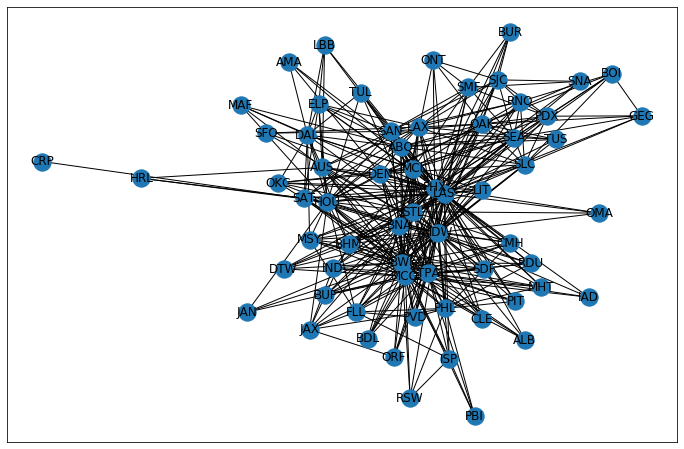

In [19]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(12,8)) # to resize the figure including our network
nx.draw_networkx(df, with_labels=True)